# Per cell-type batch distances

Used to demonstrate that BASW breaks down under uneven batch effect.

In [1]:
import numpy as np
import pickle
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc
from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math
import statsmodels.api as sm
from scipy.sparse import csr_matrix
from scipy.spatial.distance import cdist
from scipy.stats import trim_mean

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

In [2]:
dataset_keys = {
    "scib_sim1": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },
    "scib_sim2": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },
    "human_pancreas": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["tech"]
    },
    "human_lung": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },
    "neurips_bmmc": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },
    "seurat_pbmc": {
        "celltype_keys": ["celltype.l2"],
        "batch_keys": ["donor"]
    },
    "human_brain_cell_atlas": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id", "ROIGroup"]
    },
    "human_fetal_gut": {
        "celltype_keys": ["cell_name_detailed"],
        "batch_keys": ["Donor_id", "Organ", "Sample"]
    },
    "pan_cancer_dc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["dataset_id", "cancer_type"]
    },
    "human_eoe": {
        "celltype_keys": ["cell_type_anno"],
        "batch_keys": ["donor_id"]
    },
    "pan_cancer_b": {
        "celltype_keys": ["clusters"],
        "batch_keys": ["study"]
    },
    "human_retina_organoid_tissue": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["sample_id", "tissue"]
    },
    "mouse_regulatory_T": {
        "celltype_keys": ["cell.type"],
        "batch_keys": ["method", "orig.ident"]
    },
    "human_adipose": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["technology", "individual"]
    },
    "tian_multitech": {
        "celltype_keys": ["cell_line"],
        "batch_keys": ["tech"]
    },
    "nph_liver": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },
    "nph_cerebellum": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },
    "tabula_muris_lung": {
        "celltype_keys": ["cell_ontology_id"],
        "batch_keys": ["mouse.id", "tech"]
    },
    "human_pbmc_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "mouse_retina": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["dataset"]
    },
    "mouse_mammary": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },
    "macaque_retina": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },
    "human_heart": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["DonorID", "Tissue"]
    },
    "mouse_cortex_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "jurkat_293t": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["dataset"]
    },
    "3_5_pbmc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    },
    "cellranger_versions": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    }
}

In [3]:
def compute_multinomial_means(X, labels, ignore_=[]):
    means = dict()
    if isinstance(X, csr_matrix):
        X = X.toarray()
    for label in labels.unique():
        if label in ignore_:
            continue

        m = X[labels == label].sum(0)
        prop = m / np.sum(m)
        means[label] = prop
    return means


def fisher_multinomial(m1, m2):
    v = np.sum(np.sqrt(m1 * m2))
    v = np.clip(v, -1, 1)
    return 2 * np.arccos(v)


def compute_classwise_fisher(means):
    mean_vectors = np.array([means[key] for key in sorted(means.keys())])
    distances = cdist(mean_vectors, mean_vectors, fisher_multinomial)
    return pd.DataFrame(
        distances, columns=sorted(means.keys()), index=sorted(means.keys())
    )

## Compute two measures of batch unevenness

1. Coefficient of variation of Fisher-Rao distances between batches across cell types
2. Gene expression correlation between pseudobulked cell types.

In [30]:
adata_cv = {}
for dataset in dataset_keys.keys():
    print(dataset)
    adata = sc.read(f'../data/{dataset}.h5ad')
    batch_col = dataset_keys[dataset]['batch_keys'][0]
    celltype_col = dataset_keys[dataset]['celltype_keys'][0]
    
    cvs = []
    for CT_ in adata.obs[celltype_col].unique():
        adata_ct = adata[adata.obs[celltype_col] == CT_].copy()

        # Subset to just the highly variable genes
        adata_ct = adata_ct[:, adata_ct.var['highly_variable']]

        if len(adata_ct) < 100:
            print(f"Skipped cell type {CT_}, due to < {100} cells")
            continue

        means = compute_multinomial_means(
            adata_ct.layers['counts'],
            adata_ct.obs[batch_col],
        )

        pairdist = compute_classwise_fisher(means)

        D = pairdist.to_numpy()
        triu_idx = np.triu_indices_from(D, k=1)
        distances = D[triu_idx]
        ct_cv = scipy.stats.variation(distances)

        cvs.append(ct_cv)
    
    adata_cv[dataset] = cvs

scib_sim1
scib_sim2
human_pancreas
Skipped cell type schwann, due to < 100 cells
Skipped cell type mast, due to < 100 cells
Skipped cell type macrophage, due to < 100 cells
Skipped cell type epsilon, due to < 100 cells
Skipped cell type t_cell, due to < 100 cells
human_lung
Skipped cell type Ionocytes, due to < 100 cells
neurips_bmmc
Skipped cell type CD4+ T CD314+ CD45RA+, due to < 100 cells
Skipped cell type CD8+ T naive CD127+ CD26- CD101-, due to < 100 cells
Skipped cell type dnT, due to < 100 cells
Skipped cell type cDC1, due to < 100 cells
Skipped cell type T prog cycling, due to < 100 cells
seurat_pbmc
Skipped cell type CD8 Proliferating, due to < 100 cells
Skipped cell type ASDC, due to < 100 cells
Skipped cell type Eryth, due to < 100 cells
human_brain_cell_atlas
human_fetal_gut
Skipped cell type Enterocytes, due to < 100 cells
Skipped cell type BEST4+ enterocyte, due to < 100 cells
human_liver_time
pan_cancer_dc
human_eoe
Skipped cell type Monocyte (CD14), due to < 100 cells


In [75]:
adata_corr = {}
for dataset in dataset_keys.keys():
    print(dataset)
    adata = sc.read(f'../data/{dataset}.h5ad')
    batch_col = dataset_keys[dataset]['batch_keys'][0]
    celltype_col = dataset_keys[dataset]['celltype_keys'][0]
    
    corrs = []
    for CT_ in adata.obs[celltype_col].unique():
        adata_ct = adata[adata.obs[celltype_col] == CT_].copy()

        # Subset to just the highly variable genes
        adata_ct = adata_ct[:, adata_ct.var['highly_variable']]

        if len(adata_ct) < 100:
            print(f"Skipped cell type {CT_}, due to < {100} cells")
            continue

        means = compute_multinomial_means(
            adata_ct.layers['counts'],
            adata_ct.obs[batch_col],
        )

        pairdist = pd.DataFrame(means).corr(method='spearman')

        D = pairdist.to_numpy()
        triu_idx = np.triu_indices_from(D, k=1)
        distances = D[triu_idx]
        ct_corr = scipy.stats.variation(distances)

        corrs.append(ct_corr)
    
    adata_corr[dataset] = corrs

scib_sim1
scib_sim2
human_pancreas
Skipped cell type schwann, due to < 100 cells
Skipped cell type mast, due to < 100 cells
Skipped cell type macrophage, due to < 100 cells
Skipped cell type epsilon, due to < 100 cells
Skipped cell type t_cell, due to < 100 cells
human_lung
Skipped cell type Ionocytes, due to < 100 cells
neurips_bmmc
Skipped cell type CD4+ T CD314+ CD45RA+, due to < 100 cells
Skipped cell type CD8+ T naive CD127+ CD26- CD101-, due to < 100 cells
Skipped cell type dnT, due to < 100 cells
Skipped cell type cDC1, due to < 100 cells
Skipped cell type T prog cycling, due to < 100 cells
seurat_pbmc
Skipped cell type CD8 Proliferating, due to < 100 cells
Skipped cell type ASDC, due to < 100 cells
Skipped cell type Eryth, due to < 100 cells
human_brain_cell_atlas
human_fetal_gut
Skipped cell type Enterocytes, due to < 100 cells
Skipped cell type BEST4+ enterocyte, due to < 100 cells
human_liver_time
pan_cancer_dc
human_eoe
Skipped cell type Monocyte (CD14), due to < 100 cells


In [34]:
for dataset, cvs in adata_cv.items():
    print(dataset, np.nanmean(cvs))

scib_sim1 0.07379835831935609
scib_sim2 0.10699406046076798
human_pancreas 0.23278357874865663
human_lung 0.31966249529617463
neurips_bmmc 0.2809899784648942
seurat_pbmc 0.21718858656099882
human_brain_cell_atlas 0.279723516161213
human_fetal_gut 0.29943053632489325
human_liver_time 0.04923997097323474
pan_cancer_dc 0.2851778708658177
human_eoe 0.2827716078386205
pan_cancer_b 0.1743523458668903
human_retina_organoid_tissue 0.3487154239136614
mouse_regulatory_T 0.0
human_adipose 0.0
tian_multitech 0.1679956431037634
nph_liver 0.04882453927931779
nph_cerebellum 0.0
tabula_muris_lung 0.24535257679327538
human_pbmc_sequencing_techs 0.2058129422808746
mouse_retina 0.0
mouse_mammary 0.16153324739066252
macaque_retina 0.16296885802480096
human_heart 0.38172204207266935
mouse_cortex_sequencing_techs 0.13008157525677494
jurkat_293t 0.0
3_5_pbmc 0.0
cellranger_versions 0.0


In [155]:
import pickle
with open('../results/spreadsheets/adata_per_celltype_batch_distance.pkl', 'wb') as f:
    pickle.dump([adata_cv, adata_corr], f)

## BRAS vs. BASW

In [147]:
cvs_df = pd.DataFrame([(d, np.nanmean(cvs)) for d, cvs in adata_cv.items()], columns=['dataset', 'CV'])
pearson_df = pd.DataFrame([(d, np.nanmean(corrs)) for d, corrs in adata_corr.items()], columns=['dataset', 'Spearman'])

In [148]:
# This is copied from the BRAS-BASW Pearson correlations
data = {
    'dataset': [
        '3_5_pbmc', 'cellranger_versions', 'human_adipose', 'human_brain_cell_atlas',
        'human_eoe', 'human_fetal_gut', 'human_heart', 'human_lung', 'human_pancreas',
        'human_pbmc_sequencing_techs', 'human_retina_organoid_tissue', 'jurkat_293t',
        'macaque_retina', 'mouse_cortex_sequencing_techs', 'mouse_mammary', 'mouse_regulatory_T',
        'mouse_retina', 'neurips_bmmc', 'nph_cerebellum', 'nph_liver', 'pan_cancer_b',
        'pan_cancer_dc', 'scib_sim1', 'scib_sim2', 'seurat_pbmc', 'tabula_muris_lung',
        'tian_multitech'
    ],
    'rho': [
        0.9649122807017542, 0.987744829850093, 0.9899159663865545, 0.6411172796723889,
        0.54972191323693, 0.5408963585434174, 0.7512983404989653, 0.47030812324929977,
        0.7279352226720648, 0.737966537966538, 0.7449866310160428, 0.8425794215267899,
        0.917741935483871, 0.8806787082649151, 0.8909899888765294, 0.7002442002442002,
        0.742741935483871, 0.7010431484115695, 0.901209677419355, 0.9088709677419355,
        0.7393162393162392, -0.3246153846153846, 0.9248533724340174, 0.9270527859237535,
        0.835229966808914, 0.5906562847608453, 0.9553561658824817
    ]
}

corrs_df = pd.DataFrame(data)

In [149]:
df = pd.merge(cvs_df, pearson_df, on='dataset')
df = pd.merge(df, corrs_df, on='dataset')

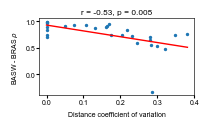

In [150]:
slope, intercept, r, p, se = stats.linregress(df['CV'], df['rho'])
x_line = np.linspace(df['CV'].min(), df['CV'].max(), 100)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(1, 1, figsize=(2, 1))
df.plot(kind='scatter', x='CV', y='rho', ax=ax, s=2)
ax.plot(x_line, y_line, color='red', linewidth=1)
plt.title(f'r = {r:.2f}, p = {p:.3f}', fontsize=6, pad=3)
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlabel('Distance coefficient of variation', fontsize=5)
plt.ylabel('BASW - BRAS $\\rho$', fontsize=5)

plt.savefig('../publication_figures/basw_bras_cv.png', dpi=200, bbox_inches='tight')
plt.show()

r = -0.61, p = 0.001


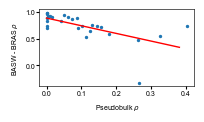

In [84]:
slope, intercept, r, p, se = stats.linregress(df['Spearman'], df['rho'])
x_line = np.linspace(df['CV'].min(), df['CV'].max(), 100)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(1, 1, figsize=(2, 1))
df.plot(kind='scatter', x='Spearman', y='rho', ax=ax, s=2)
ax.plot(x_line, y_line, color='red', linewidth=1)
plt.title(f'r = {r:.2f}, p = {p:.3f}', fontsize=6, pad=3)
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlabel('Pseudobulk $\\rho$', fontsize=5)
plt.ylabel('BASW - BRAS $\\rho$', fontsize=5)

# plt.savefig('../publication_figures/basw_bras_pseudobulk_corr.png', dpi=200, bbox_inches='tight')
plt.show()

## BASW vs KBET

In [151]:
# BASW-KBET Pearson correlations
corrs2 = pd.DataFrame({
    'dataset': [
        '3_5_pbmc', 'cellranger_versions', 'human_adipose', 'human_brain_cell_atlas',
        'human_eoe', 'human_fetal_gut', 'human_heart', 'human_lung', 'human_pancreas',
        'human_pbmc_sequencing_techs', 'human_retina_organoid_tissue', 'jurkat_293t',
        'macaque_retina', 'mouse_cortex_sequencing_techs', 'mouse_mammary', 'mouse_regulatory_T',
        'mouse_retina', 'neurips_bmmc', 'nph_cerebellum', 'nph_liver', 'pan_cancer_b',
        'pan_cancer_dc', 'scib_sim1', 'scib_sim2', 'seurat_pbmc', 'tabula_muris_lung',
        'tian_multitech'
    ],
    'rho': [
        0.7719298245614034, 0.9367545683335156, 0.7212885154061626, 0.5034102246667694,
        -0.018909899888765295, -0.008403361344537815, 0.23355136590996534, -0.04565826330532213,
        0.3779352226720648, 0.42007722007722015, 0.3897058823529412, 0.78117591275486,
        0.5241935483870969, 0.5938697318007663, 0.7085650723025584, 0.7588522588522589,
        0.6137096774193549, 0.11427216690374584, 0.503225806451613, 0.6455645161290323,
        0.6507936507936508, -0.5407692307692307, 0.8638785509098793, 0.6810270840358212,
        0.24964438122332858, 0.3659621802002225, 0.8781733929782402
    ]
})
corrs2

,dataset,rho
0,3_5_pbmc,0.771930
1,cellranger_versions,0.936755
2,human_adipose,0.721289
3,human_brain_cell_atlas,0.503410
4,human_eoe,-0.018910
5,human_fetal_gut,-0.008403
6,human_heart,0.233551
7,human_lung,-0.045658
8,human_pancreas,0.377935
9,human_pbmc_sequencing_techs,0.420077


In [152]:
df = pd.merge(cvs_df, pearson_df, on='dataset')
df = pd.merge(df, corrs2, on='dataset')

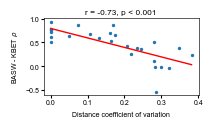

In [154]:
import numpy as np
from scipy import stats

# Compute line of best fit
slope, intercept, r, p, se = stats.linregress(df['CV'], df['rho'])
x_line = np.linspace(df['CV'].min(), df['CV'].max(), 100)
y_line = slope * x_line + intercept

# Plot
fig, ax = plt.subplots(1, 1, figsize=(2, 1))
df.plot(kind='scatter', x='CV', y='rho', ax=ax, s=2)
ax.plot(x_line, y_line, color='red', linewidth=1)
# print(f'r = {r:.2f}, p = {p:.3f}')
plt.title(f'r = {r:.2f}, p < 0.001', fontsize=6, pad=3)
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlabel('Distance coefficient of variation', fontsize=5)
plt.ylabel('BASW - KBET $\\rho$', fontsize=5)

plt.savefig('../publication_figures/basw_kbet_cv.png', dpi=200, bbox_inches='tight')
plt.show()

r = -0.61, p = 0.001


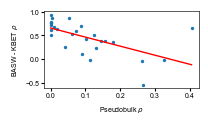

In [87]:
import numpy as np
from scipy import stats

# Compute line of best fit
slope, intercept, r, p, se = stats.linregress(df['Spearman'], df['rho'])
x_line = np.linspace(df['Spearman'].min(), df['Spearman'].max(), 100)
y_line = slope * x_line + intercept

# Plot
fig, ax = plt.subplots(1, 1, figsize=(2, 1))
df.plot(kind='scatter', x='Spearman', y='rho', ax=ax, s=2)
ax.plot(x_line, y_line, color='red', linewidth=1)
print(f'r = {r:.2f}, p = {p:.3f}')
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.xlabel('Pseudobulk $\\rho$', fontsize=5)
plt.ylabel('BASW - KBET $\\rho$', fontsize=5)

# plt.savefig('../publication_figures/basw_kbet_pseudobulk_corr.png', dpi=200, bbox_inches='tight')
plt.show()

## Distances between batches in the human fetal gut dataset

In [89]:
dataset = 'human_fetal_gut'
adata = sc.read(f'../data/{dataset}.h5ad')
batch_col = dataset_keys[dataset]['batch_keys'][0]
celltype_col = dataset_keys[dataset]['celltype_keys'][0]

In [94]:
adata.obs[celltype_col].cat.categories

Index(['Arterial endothelial cell', 'BEST4+ enterocyte', 'Enteric neurons',
       'Erythroblasts', 'FOXL1+ fibroblasts', 'FRZB+ fibroblasts', 'Goblet',
       'Interstitial cells of Cajal', 'LGR5 stem', 'Colonocytes',
       'Lymphatic endothelial cell', 'Neural crest cells',
       'Uniform progenitors', 'Enterocytes', 'Smooth muscle cells',
       'Serosa/mesothelial cells', 'Venous endothelial cell',
       'WNT4+ fibroblasts', 'G2M/S enterocytes', 'Early enterocyte',
       'Enterocyte', 'Enteroendocrine', 'NTS+ epithelial cells',
       'Immune cells', 'Mesoderm 1', 'Mesoderm 2', 'Myofibroblast',
       'Pericyte'],
      dtype='object')

In [98]:
cvs = {}
for CT_ in adata.obs[celltype_col].unique():
    adata_ct = adata[adata.obs[celltype_col] == CT_].copy()

    # Subset to just the highly variable genes
    adata_ct = adata_ct[:, adata_ct.var['highly_variable']]

    if len(adata_ct) < 100:
        print(f"Skipped cell type {CT_}, due to < {100} cells")
        continue

    means = compute_multinomial_means(
        adata_ct.layers['counts'],
        adata_ct.obs['PCW'],
    )

    pairdist = compute_classwise_fisher(means)
    cvs[CT_] = (pairdist)

Skipped cell type Enterocytes, due to < 100 cells
Skipped cell type BEST4+ enterocyte, due to < 100 cells


In [102]:
order = ['F6.1', 'F6.7', 'F6.9', 'F7.9', 'F8.4', 'F9.2', 'F9.9', 'F10', "F10.2"]

In [108]:
arr = []
for ct_, cv in cvs.items():
    try:
        arr.append(cv.loc[order, order].to_numpy())
    except KeyError:
        pass

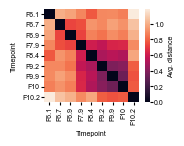

In [141]:
fig, ax = plt.subplots(1, 1, figsize=(1.8, 1.45))

sns.heatmap(
    pd.DataFrame(np.mean(arr, axis=0), index=order, columns=order),
    ax=ax,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Avg. distance"},
)
cbar = ax.collections[0].colorbar
cbar.set_label("Avg. distance", fontsize=5, labelpad=3)
cbar.ax.tick_params(axis="both", which="major", width=0.8, length=2, labelsize=5, pad=1)

ax.tick_params(axis="both", which="major", width=0.8, length=2, labelsize=5, pad=1)

for spine in ax.spines.values():
    spine.set_linewidth(0.45)

plt.tight_layout()
plt.xlabel('Timepoint', fontsize=5)
plt.ylabel('Timepoint', fontsize=5)
plt.savefig('../publication_figures/human_fetal_gut_distances.png', dpi=200, bbox_inches='tight')
plt.show()